In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
import json
import hashlib
import re
import unicodedata

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

# PROJECT CONFIGURATION

CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "dataset").exists():
    PROJECT_DIR = CURRENT_DIR

elif (CURRENT_DIR.parent / "dataset").exists():
    PROJECT_DIR = CURRENT_DIR.parent

else:
    raise FileNotFoundError(
        "Dataset folder not found. Check your notebook location."
    )

DATASET_DIR = PROJECT_DIR / "dataset"

REPORT_DIR = PROJECT_DIR / "preprocessing_reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Report directory:", REPORT_DIR)

Project directory: d:\College Work\UnsupervisedProject
Dataset directory: d:\College Work\UnsupervisedProject\dataset
Report directory: d:\College Work\UnsupervisedProject\preprocessing_reports


In [ ]:

# DATASET LOADING

FILES = {
    "train": "darkreddit_train.csv",
    "validation": "darkreddit_val.csv",
    "test": "darkreddit_test.csv"
}

datasets = {}

for split_name, filename in FILES.items():

    file_path = DATASET_DIR / filename

    if not file_path.exists():
        print(f"Warning: {filename} not found.")
        continue

    df = pd.read_csv(
        file_path,
        usecols=["text1", "text2"],
        encoding="utf-8"
    )

    datasets[split_name] = df

    print(f"\n{split_name.upper()} DATASET")
    print("-" * 40)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())


TRAIN DATASET
----------------------------------------
Shape: (204, 2)
Columns: ['text1', 'text2']

VALIDATION DATASET
----------------------------------------
Shape: (412, 2)
Columns: ['text1', 'text2']

TEST DATASET
----------------------------------------
Shape: (412, 2)
Columns: ['text1', 'text2']


In [12]:
# ============================================================
# DATASET UNDERSTANDING
# ============================================================

train_df = datasets["train"]

print("Dataset information:")
train_df.info()

print("\nFirst 5 examples:")
print(train_df.head())

print("\nDataset shape:")
print(train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text1   204 non-null    str  
 1   text2   204 non-null    str  
dtypes: str(2)
memory usage: 1.1 MB

First 5 examples:
                                               text1  \
0  Separate but equal Come on sir , now which pic...   
1  Facts . Only reason I ended up learning was be...   
2  , you think your nose wo n't hurt from clean c...   
3  > y on up until before it got shut down . So ,...   
4  They can track through the blockchain transact...   

                                               text2  
0  is their MO . Lol That ’s why in they made the...  
1  have to take opsec seriously , due to the pote...  
2  strawman about law enforcement . " Something s...  
3  Yeah , it 's not a police state in the . Ridic...  
4  a private coin and is difficult to trace if no...  

Dataset shape:
(204, 2)

In [11]:
# ============================================================
# MISSING VALUE ANALYSIS
# ============================================================

for split_name, df in datasets.items():

    print(f"\n{split_name.upper()} MISSING VALUES")
    print("-" * 40)

    missing_values = df.isnull().sum()

    print(missing_values)

    total_missing = missing_values.sum()

    print("Total missing values:", total_missing)


TRAIN MISSING VALUES
----------------------------------------
text1    0
text2    0
dtype: int64
Total missing values: 0

VALIDATION MISSING VALUES
----------------------------------------
text1    0
text2    0
dtype: int64
Total missing values: 0

TEST MISSING VALUES
----------------------------------------
text1    0
text2    0
dtype: int64
Total missing values: 0


In [13]:
# ============================================================
# EMPTY TEXT ANALYSIS
# ============================================================

for split_name, df in datasets.items():

    print(f"\n{split_name.upper()} EMPTY TEXT ANALYSIS")
    print("-" * 40)

    for column in ["text1", "text2"]:

        empty_count = (
            df[column]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        )

        print(f"{column}: {empty_count} empty texts")


TRAIN EMPTY TEXT ANALYSIS
----------------------------------------
text1: 0 empty texts
text2: 0 empty texts

VALIDATION EMPTY TEXT ANALYSIS
----------------------------------------
text1: 0 empty texts
text2: 0 empty texts

TEST EMPTY TEXT ANALYSIS
----------------------------------------
text1: 0 empty texts
text2: 0 empty texts


In [8]:
# ============================================================
# TEXT LENGTH ANALYSIS
# ============================================================

for split_name, df in datasets.items():

    print(f"\n{split_name.upper()} TEXT LENGTH")
    print("-" * 40)

    for column in ["text1", "text2"]:

        lengths = (
            df[column]
            .dropna()
            .astype(str)
            .str.len()
        )

        print(f"\n{column}")

        print("Minimum length:", lengths.min())
        print("Maximum length:", lengths.max())
        print("Mean length:", round(lengths.mean(), 2))
        print("Median length:", lengths.median())


TRAIN TEXT LENGTH
----------------------------------------

text1
Minimum length: 670
Maximum length: 18638
Mean length: 2789.12
Median length: 1691.0

text2
Minimum length: 627
Maximum length: 19643
Mean length: 2856.64
Median length: 1963.5

VALIDATION TEXT LENGTH
----------------------------------------

text1
Minimum length: 620
Maximum length: 20543
Mean length: 2439.64
Median length: 1787.0

text2
Minimum length: 654
Maximum length: 19715
Mean length: 2380.51
Median length: 1798.0

TEST TEXT LENGTH
----------------------------------------

text1
Minimum length: 610
Maximum length: 49312
Mean length: 2764.36
Median length: 1849.0

text2
Minimum length: 636
Maximum length: 99003
Mean length: 3278.2
Median length: 1785.0


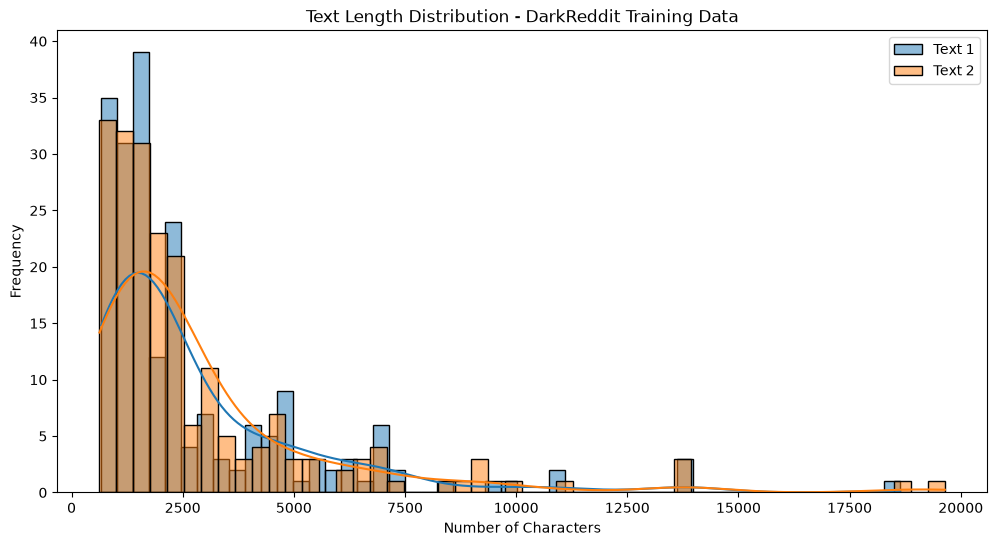

In [14]:
# ============================================================
# TEXT LENGTH VISUALIZATION
# ============================================================

train_df = datasets["train"]

text1_lengths = train_df["text1"].dropna().astype(str).str.len()
text2_lengths = train_df["text2"].dropna().astype(str).str.len()

plt.figure(figsize=(12, 6))

sns.histplot(
    text1_lengths,
    bins=50,
    kde=True,
    label="Text 1",
    alpha=0.5
)

sns.histplot(
    text2_lengths,
    bins=50,
    kde=True,
    label="Text 2",
    alpha=0.5
)

plt.title("Text Length Distribution - DarkReddit Training Data")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.legend()

plt.show()

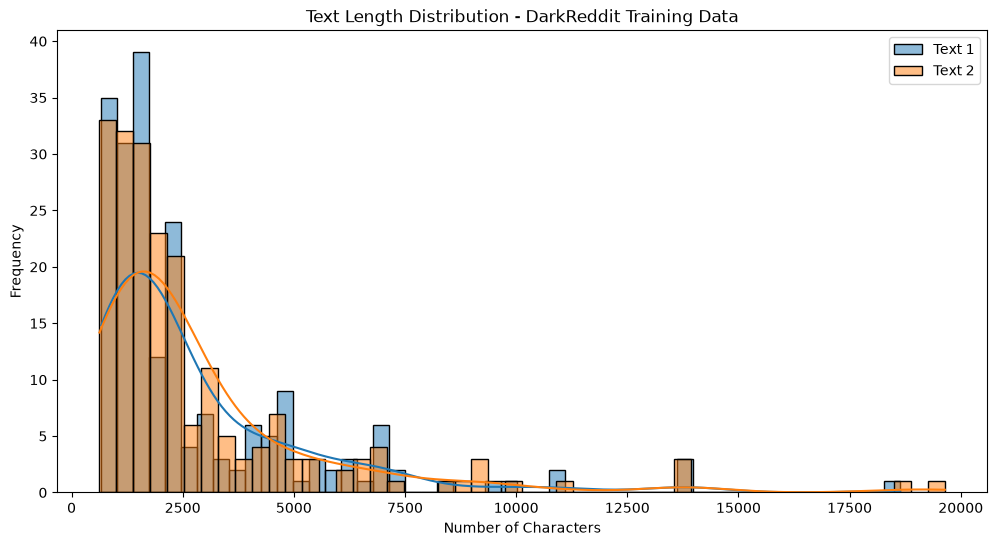

In [15]:
# ============================================================
# TEXT LENGTH VISUALIZATION
# ============================================================

train_df = datasets["train"]

text1_lengths = train_df["text1"].dropna().astype(str).str.len()
text2_lengths = train_df["text2"].dropna().astype(str).str.len()

plt.figure(figsize=(12, 6))

sns.histplot(
    text1_lengths,
    bins=50,
    kde=True,
    label="Text 1",
    alpha=0.5
)

sns.histplot(
    text2_lengths,
    bins=50,
    kde=True,
    label="Text 2",
    alpha=0.5
)

plt.title("Text Length Distribution - DarkReddit Training Data")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [16]:
# ============================================================
# DUPLICATE DETECTION NORMALIZATION
# ============================================================

def normalize_for_duplicate_check(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # Unicode normalization
    text = unicodedata.normalize("NFKC", text)

    # Remove null characters
    text = text.replace("\x00", "")

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove leading and trailing whitespace
    text = text.strip()

    return text

In [13]:
# ============================================================
# HASH FUNCTION
# ============================================================

def generate_text_hash(text):

    normalized_text = normalize_for_duplicate_check(text)

    return hashlib.sha256(
        normalized_text.encode("utf-8")
    ).hexdigest()

print("Hash function created successfully!")

Hash function created successfully!


In [14]:
# ============================================================
# DUPLICATE PAIR ANALYSIS
# ============================================================

duplicate_reports = {}

for split_name, df in datasets.items():

    print(f"\n{split_name.upper()} DUPLICATE ANALYSIS")
    print("-" * 40)

    exact_duplicate_rows = df.duplicated().sum()

    ordered_pairs = []
    unordered_pairs = []

    for _, row in df.iterrows():

        hash1 = generate_text_hash(row["text1"])
        hash2 = generate_text_hash(row["text2"])

        ordered_pairs.append((hash1, hash2))

        unordered_pairs.append(
            tuple(sorted([hash1, hash2]))
        )

    duplicate_ordered_pairs = (
        len(ordered_pairs) - len(set(ordered_pairs))
    )

    duplicate_unordered_pairs = (
        len(unordered_pairs) - len(set(unordered_pairs))
    )

    reversed_pair_duplicates = (
        duplicate_unordered_pairs - duplicate_ordered_pairs
    )

    duplicate_reports[split_name] = {
        "exact_duplicate_rows": int(exact_duplicate_rows),
        "duplicate_ordered_pairs": int(duplicate_ordered_pairs),
        "duplicate_unordered_pairs": int(duplicate_unordered_pairs),
        "reversed_pair_duplicates": int(reversed_pair_duplicates)
    }

    print("Exact duplicate rows:", exact_duplicate_rows)
    print("Duplicate ordered pairs:", duplicate_ordered_pairs)
    print("Duplicate unordered pairs:", duplicate_unordered_pairs)
    print("Reversed pair duplicates:", reversed_pair_duplicates)


TRAIN DUPLICATE ANALYSIS
----------------------------------------
Exact duplicate rows: 0
Duplicate ordered pairs: 0
Duplicate unordered pairs: 1
Reversed pair duplicates: 1

VALIDATION DUPLICATE ANALYSIS
----------------------------------------
Exact duplicate rows: 0
Duplicate ordered pairs: 0
Duplicate unordered pairs: 1
Reversed pair duplicates: 1

TEST DUPLICATE ANALYSIS
----------------------------------------
Exact duplicate rows: 0
Duplicate ordered pairs: 0
Duplicate unordered pairs: 0
Reversed pair duplicates: 0


In [15]:
# ============================================================
# CROSS-SPLIT TEXT OVERLAP
# ============================================================

split_text_hashes = {}

for split_name, df in datasets.items():

    hashes = set()

    for column in ["text1", "text2"]:

        column_hashes = (
            df[column]
            .dropna()
            .map(generate_text_hash)
        )

        hashes.update(column_hashes)

    split_text_hashes[split_name] = hashes


cross_split_overlap = {}

split_names = list(split_text_hashes.keys())

for i in range(len(split_names)):

    for j in range(i + 1, len(split_names)):

        split_a = split_names[i]
        split_b = split_names[j]

        overlap = (
            split_text_hashes[split_a]
            & split_text_hashes[split_b]
        )

        cross_split_overlap[
            f"{split_a}_vs_{split_b}"
        ] = len(overlap)


print("Cross-split exact text overlap:")

for comparison, count in cross_split_overlap.items():

    print(f"{comparison}: {count}")

Cross-split exact text overlap:
train_vs_validation: 0
train_vs_test: 0
validation_vs_test: 0


In [25]:

# ============================================================
# PROFILING SUMMARY
# ============================================================

summary_rows = []

for split_name, df in datasets.items():

    summary_rows.append({
        "split": split_name,
        "rows": df.shape[0],
        "columns": df.shape[1],

        "missing_text1": df["text1"].isnull().sum(),
        "missing_text2": df["text2"].isnull().sum(),

        "empty_text1": (
            df["text1"]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        ),

        "empty_text2": (
            df["text2"]
            .fillna("")
            .astype(str)
            .str.strip()
            .eq("")
            .sum()
        )
    })

profiling_summary = pd.DataFrame(summary_rows)

print(profiling_summary)


        split  rows  columns  missing_text1  missing_text2  empty_text1  \
0       train   204        2              0              0            0   
1  validation   412        2              0              0            0   
2        test   412        2              0              0            0   

   empty_text2  
0            0  
1            0  
2            0  


In [27]:

# ============================================================
# SAVE PREPROCESSING REPORT
# ============================================================

preprocessing_report = {
    "project": "DarkID",
    "stage": "Dataset Profiling",
    "label_column_used": False,

    "profiling_summary": profiling_summary.to_dict(
        orient="records"
    )
}

# Save report as JSON
report_path = REPORT_DIR / "profiling_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(
        preprocessing_report,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Preprocessing report saved successfully!")
print(f"Report location: {report_path}")


Preprocessing report saved successfully!
Report location: d:\College Work\UnsupervisedProject\preprocessing_reports\profiling_report.json
